# 03 · Models on URL features

**Why:** the app only gets a URL from the user. It can't provide the dataset's page-content columns (`LineOfCode`, `NoOfImage`, …) or `URLSimilarityIndex`. So we compute our own features from the URL string alone (`src/phishguard/features.py`, decision D7) and train Random Forest and XGBoost on them.

Published URL-only reference: XGBoost 99.74% (Frontiers in Computer Science, 2026).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from phishguard.data import load_clean, TARGET
from phishguard.split import get_splits
from phishguard.features import extract_features
from phishguard.modeling import param_grid, tune, fit_and_test
from phishguard.evaluate import save_result

df = load_clean()
splits = get_splits(df)
y = df[TARGET]
X = extract_features(df["URL"])
X.shape

(234204, 39)

## The features

| Group | Features | Idea |
|---|---|---|
| Size | `url_length`, `host_length`, `path_length`, `query_length`, `domain_length`, `tld_length` | Phishing URLs are often long, to hide the real domain |
| Character counts | `num_digits`, `num_dots`, `num_hyphens`, `num_slashes`, `num_at`, `num_percent`, … and ratios | Random or obfuscated URLs have unusual character mixes |
| Host structure | `num_subdomains`, `host_dots`, `host_hyphens`, `has_ip`, `has_port`, `has_www` | `paypal.com.secure-login.xyz` puts a brand in the subdomain |
| Scheme | `is_https` | |
| Platform | `on_hosting_platform`, `is_shortener` | Free hosting (`web.app`, `weebly`) and shorteners are popular with attackers |
| Path & query | `path_depth`, `num_query_params`, `has_fragment`, `double_slash_in_path` | |
| Words | `suspicious_words` (login, verify, account, …), `longest_token` | |
| Randomness | `url_entropy`, `host_entropy` | Generated domains like `x7q9kz.top` have high entropy |

In [2]:
X.head()

,url_length,num_letters,num_digits,letter_ratio,digit_ratio,special_ratio,num_dots,num_hyphens,num_underscores,num_slashes,...,on_hosting_platform,is_shortener,path_depth,num_query_params,has_fragment,double_slash_in_path,suspicious_words,longest_token,url_entropy,host_entropy
0,32,27,0,0.843750,0.0,0.156250,2,0,0,2,...,0,0,0,0,0,0,1,16,3.929229,3.657268
1,24,18,0,0.750000,0.0,0.250000,2,1,0,2,...,0,0,0,0,0,0,0,5,3.970176,3.327820
2,30,24,0,0.800000,0.0,0.200000,3,0,0,2,...,0,0,0,0,0,0,0,12,4.164735,3.629220
3,27,22,0,0.814815,0.0,0.185185,2,0,0,2,...,0,0,0,0,0,0,0,11,4.060262,3.576618
4,34,29,0,0.852941,0.0,0.147059,2,0,0,2,...,0,0,0,0,0,0,0,18,3.917626,3.430457


## How do the classes differ?

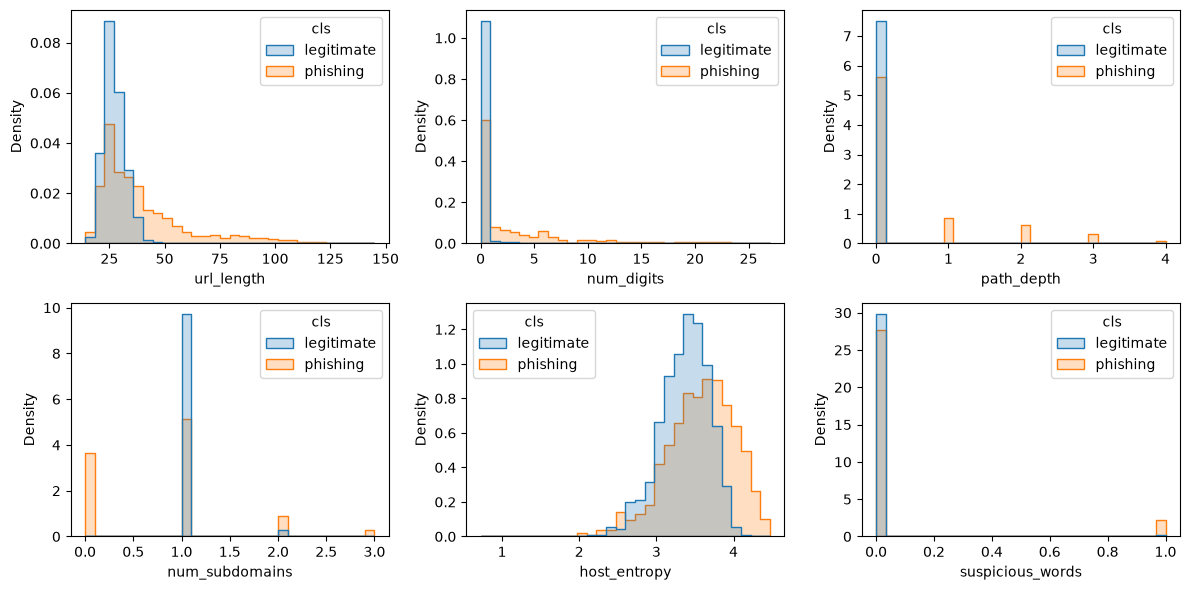

In [3]:
cols = ["url_length", "num_digits", "path_depth", "num_subdomains", "host_entropy", "suspicious_words"]
plot_df = X[cols].assign(cls=y.map({0: "legitimate", 1: "phishing"}))
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, col in zip(axes.flat, cols):
    clip = plot_df[col].quantile(0.99)
    sns.histplot(data=plot_df[plot_df[col] <= clip], x=col, hue="cls", stat="density",
                 common_norm=False, bins=30, element="step", ax=ax)
fig.tight_layout()
plt.show()

In [4]:
X.groupby(y.map({0: "legitimate", 1: "phishing"})).mean().T.round(3)

is_phishing,legitimate,phishing
url_length,27.229,45.769
num_letters,21.933,34.153
num_digits,0.051,4.329
letter_ratio,0.800,0.754
digit_ratio,0.002,0.064
special_ratio,0.198,0.181
num_dots,2.162,2.389
num_hyphens,0.083,0.704
num_underscores,0.000,0.082
num_slashes,2.000,2.646


Legitimate URLs are short, have no path and no digits. Phishing URLs vary much more. We look into *why* the legitimate side is so uniform in Milestone 3.

## 1. Random Forest

In [5]:
make_rf = lambda max_depth, min_samples_leaf: RandomForestClassifier(
    n_estimators=300, max_depth=max_depth, min_samples_leaf=min_samples_leaf, n_jobs=-1, random_state=42)
table, best = tune(make_rf, param_grid(max_depth=[None, 30], min_samples_leaf=[1, 2]), X, y, splits)
table

,max_depth,min_samples_leaf,val_accuracy,val_roc_auc
0,NaN,1,0.997353,0.998014
1,30.0,1,0.997324,0.997853
2,NaN,2,0.997296,0.998165
3,30.0,2,0.997296,0.998155


In [6]:
rf, t, m = fit_and_test(make_rf(**best), X, y, splits)
save_result("Random Forest (URL features)", "URL features", t, m)
pd.Series(m).round(5)

accuracy         0.99681
precision        0.99966
recall           0.99282
f1               0.99623
roc_auc          0.99746
tn           20218.00000
fp               5.00000
fn             107.00000
tp           14800.00000
dtype: float64

## 2. XGBoost

In [7]:
make_xgb = lambda max_depth, n_estimators: XGBClassifier(
    max_depth=max_depth, n_estimators=n_estimators, learning_rate=0.1, n_jobs=-1, random_state=42)
table, best = tune(make_xgb, param_grid(max_depth=[6, 8, 10], n_estimators=[300, 800]), X, y, splits)
table

,max_depth,n_estimators,val_accuracy,val_roc_auc
0,10,800,0.997324,0.997612
1,6,300,0.997296,0.998226
2,6,800,0.997296,0.997857
3,10,300,0.997296,0.997851
4,8,300,0.997239,0.997954
5,8,800,0.997239,0.997672


In [8]:
xgb, t, m = fit_and_test(make_xgb(**best), X, y, splits)
save_result("XGBoost (URL features)", "URL features", t, m)
pd.Series(m).round(5)

accuracy         0.99675
precision        0.99946
recall           0.99289
f1               0.99616
roc_auc          0.99707
tn           20215.00000
fp               8.00000
fn             106.00000
tp           14801.00000
dtype: float64

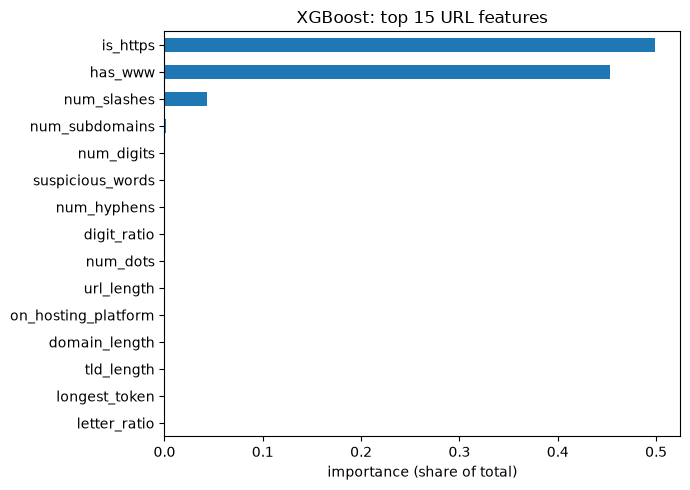

In [9]:
pd.Series(xgb.feature_importances_, index=X.columns).sort_values().tail(15).plot.barh(figsize=(7, 5))
plt.title("XGBoost: top 15 URL features")
plt.xlabel("importance (share of total)")
plt.tight_layout()
plt.show()

## 3. What does it still get wrong?

We look at validation errors. Test stays untouched apart from the single final score.

In [10]:
_, val_idx, _ = splits
val_prob = pd.Series(xgb.predict_proba(X.loc[val_idx])[:, 1], index=val_idx)
missed = df.loc[val_idx][(y[val_idx] == 1) & (val_prob < t)]
print(f"missed phishing URLs on validation: {len(missed)}")
print("share that are a bare https://www.<domain> homepage:",
      missed["URL"].str.match(r"^https://www\.[^/]+$").mean())
missed["URL"].head(10)

missed phishing URLs on validation: 91
share that are a bare https://www.<domain> homepage: 1.0


1497                   https://www.solutionfun.info
1599               https://www.ioginunlcovlabcp.com
4084                            https://www.ridm.in
4668                 https://www.bendiqo-log-au.com
6825               https://www.ahsansupermarket.com
8439     https://www.kuronekoyamato.ok-hospital.com
15189          https://www.bendigo-verification.com
15327                    https://www.alhashimia.net
18076                        https://www.mndnrd.top
23685                    https://www.orderedami.com
Name: URL, dtype: str

Almost every missed phishing URL is a bare `https://www.<domain>` homepage, which is exactly what *every* legitimate URL in this dataset looks like. For these URLs the only clue left is the domain name itself: typosquats like `ncsbarnk` or `lcioud`, and cheap TLDs like `.top`.

Character-level models read the domain name directly, which is what notebook 04 does.